# Proyecto de Aula – Fase 2: Desarrollo y Modelado
**Clasificación y priorización automática de PQRS por urgencia y tipo en el sector salud mediante PLN**

Grupo 02 · Inteligencia Artificial · Ingeniería de Sistemas, 7.º semestre · Valledupar, 2026

**Contenido**
1. Configuración y carga de datos
2. Limpieza y preprocesamiento (NLTK)
3. Partición estratificada 80/20
4. Modelos de referencia (*baseline*)
5. Modelos con TF-IDF: Naive Bayes, Random Forest y SVM lineal
6. Ajuste de hiperparámetros con validación cruzada
7. TruncatedSVD + LDA (reducción de dimensionalidad supervisada)
8. Evaluación final en el conjunto de prueba
9. Ajuste del umbral para la clase «Alta»
10. Análisis de errores
11. Techo teórico de desempeño del dataset
12. Clasificación de tipo y tema
13. Guardado del modelo y resultados

## 1. Configuración y carga de datos

In [1]:
# Si se ejecuta en Google Colab, instalar dependencias (en local ya deberían estar)
try:
    import google.colab  # noqa
    !pip -q install nltk scikit-learn seaborn
except ImportError:
    pass

import os, re, time, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
warnings.filterwarnings('ignore')

import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.decomposition import TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
ORDEN = ['Baja', 'Media', 'Alta']

# Raíz del proyecto: todas las salidas (figs/, results/, models/) se guardan allí, sin importar
# desde qué carpeta se ejecute el notebook. Así la aplicación (app.py) lee el mismo modelo que se entrena aquí.
RAIZ = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
def ruta(*partes): return os.path.join(RAIZ, *partes)
for d in ('figs', 'results', 'models'): os.makedirs(ruta(d), exist_ok=True)

RUTA = ruta('data', 'pqrs_dataset_sintetico.csv')
if not os.path.exists(RUTA):
    RUTA = 'pqrs_dataset_sintetico.csv'      # copia local junto al notebook (p. ej. Colab)
if not os.path.exists(RUTA):                 # en Colab: subir el CSV
    from google.colab import files
    files.upload()
df_raw = pd.read_csv(RUTA)
print(df_raw.shape)
df_raw.head(3)

(3000, 10)


,id_pqrs,fecha_radicacion,canal,entidad,ciudad,regimen,tipo,tema,urgencia,texto
0,PQRS-2026801,2025-11-10,Web,EPS Sanar,Valledupar,Especial,Petición,Medicamentos,Alta,Cordial saludo señores. mi hijo menor de 49 añ...
1,PQRS-2026190,2025-07-03,Web,Clínica Valledupar,Aguachica,Especial,Queja,Medicamentos,Alta,"Cordial saludo senores. mi madre, una adulta m..."
2,PQRS-2026817,2025-10-08,Web,EPS Salud Total,Curumaní,Contributivo,Petición,Asistencial,Media,Por medio del presente canal quiero manifestar...


## 2. Limpieza y preprocesamiento

**Decisiones de limpieza** (justificadas en el EDA de la Fase 1):
- Se eliminan los registros con **texto nulo**: sin texto no hay nada que clasificar.
- Se eliminan los **textos duplicados** (se conserva la primera aparición) *antes* de dividir los datos, para que el mismo texto no quede a la vez en entrenamiento y prueba (fuga de información).
- Eliminar duplicados del texto original **no basta**: dos textos que difieren solo en puntuación, edad, tildes o mayúsculas llegan idénticos al modelo después del preprocesamiento. Por eso, en la sección 3, los textos equivalentes **tras la normalización** se agrupan y cada grupo queda en una sola partición (entrenamiento o prueba, y un solo pliegue de la validación cruzada). No se elimina ninguna fila ni se altera ninguna etiqueta.
- `canal`, `ciudad`, `regimen` (con nulos) no se usan como predictores: se sortean de forma independiente de la urgencia y quedan reservados para el tablero de la Fase 3.

**Preprocesamiento del texto (NLTK):** minúsculas → quitar tildes (así «señores» y «senores» quedan iguales, ya que el dataset mezcla ambas formas) → quitar signos y dígitos → *stopwords* en español → *stemming* Snowball.
Se **conservan** las palabras de negación («no», «sin», «ni», «nada»), porque «no ha recibido el medicamento» cambia el sentido de la frase.

In [2]:
n0 = len(df_raw)
df = df_raw.dropna(subset=['texto'])
n1 = len(df)
df = df.drop_duplicates(subset=['texto']).reset_index(drop=True)
print(f'Registros originales: {n0} | sin texto nulo: {n1} | sin duplicados: {len(df)}')
print(f'Eliminados: {n0-len(df)} ({(n0-len(df))/n0:.1%})')
print('\nUrgencia (tras limpieza):'); print(df['urgencia'].value_counts(normalize=True).reindex(ORDEN).round(3))

Registros originales: 3000 | sin texto nulo: 2992 | sin duplicados: 2917
Eliminados: 83 (2.8%)

Urgencia (tras limpieza):
urgencia
Baja     0.415
Media    0.390
Alta     0.194
Name: proportion, dtype: float64


In [3]:
def quitar_tildes(t):
    return ''.join(c for c in unicodedata.normalize('NFD', t) if unicodedata.category(c) != 'Mn')

STOP = {quitar_tildes(w) for w in stopwords.words('spanish')} - {'no', 'sin', 'ni', 'nada'}
STEM = SnowballStemmer('spanish')

def preprocesar(texto):
    t = quitar_tildes(str(texto).lower())
    t = re.sub(r'[^a-z\s]', ' ', t)
    return ' '.join(STEM.stem(w) for w in t.split() if w not in STOP and len(w) > 1)

df['texto_limpio'] = df['texto'].apply(preprocesar)
for i in [0, 1, 2]:
    print('ORIGINAL:', df['texto'][i]); print('LIMPIO  :', df['texto_limpio'][i]); print()

ORIGINAL: Cordial saludo señores. mi hijo menor de 49 años, fue rechazado en urgencias a pesar de presentar un cuadro clínico crítico. Exijo una solución inmediata a etse problema.
LIMPIO  : cordial salud senor hij menor anos rechaz urgenci pes present cuadr clinic critic exij solucion inmediat etse problem

ORIGINAL: Cordial saludo senores. mi madre, una adulta mayor de 82 anos, no ha recibido la Insulina que es de vida o muerte para su tratamiento. Agradezco su pronta respuesta de acuerdo a la ley.
LIMPIO  : cordial salud senor madr adult mayor anos no recib insulin vid muert tratamient agradezc pront respuest acuerd ley

ORIGINAL: Por medio del presente canal quiero manifestar que mi hijo menor de 44 anos, fue a reclamar Insulina y le dijeron que no hay inventario en la farmacia. Ademas, no le han asignado la cita de Medicina General desde hace 2 horas. Agradezco su pronta respuesta de acuerdo a la ley.
LIMPIO  : medi present canal quier manifest hij menor anos reclam insulin dijero

## 3. Partición estratificada y agrupada 80/20, y esquema de validación
La partición se estratifica por **urgencia**, se fija la semilla y se **agrupa por texto procesado** (`StratifiedGroupKFold`): todos los registros cuyo texto, ya normalizado, es idéntico quedan juntos en entrenamiento o juntos en prueba. La validación cruzada de 5 particiones usa el mismo criterio, **solo sobre el 80 % de entrenamiento**. Todas las decisiones (hiperparámetros, selección del modelo, umbral) se toman con esa validación; el 20 % de prueba se usa una única vez, al final.


In [4]:
X = df['texto_limpio']; y = df['urgencia']
# Textos equivalentes tras la normalización => mismo grupo (no se separan entre entrenamiento y prueba)
grupos = X.factorize()[0]
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_te = next(sgkf.split(X, y, groups=grupos))      # 1 de 5 particiones ≈ 20 % para prueba
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
g_tr = grupos[idx_tr]
# Validación cruzada agrupada: lista de (entrenamiento, validación) válida para cross_val_score, GridSearchCV y cross_val_predict
cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_tr, y_tr, groups=g_tr))

assert set(X_tr).isdisjoint(set(X_te)), 'Hay textos procesados en entrenamiento y prueba a la vez'
print('Entrenamiento:', len(X_tr), '| Prueba:', len(X_te))
print('Textos procesados distintos -> entrenamiento:', X_tr.nunique(), '| prueba:', X_te.nunique(), '| compartidos:', len(set(X_tr) & set(X_te)))
print(pd.DataFrame({'train': y_tr.value_counts(normalize=True), 'test': y_te.value_counts(normalize=True)}).reindex(ORDEN).round(3))
print('Casos de clase Alta en prueba:', (y_te == 'Alta').sum())


Entrenamiento: 2333 | Prueba: 584
Textos procesados distintos -> entrenamiento: 2149 | prueba: 544 | compartidos: 0
          train   test
urgencia              
Baja      0.415  0.416
Media     0.390  0.390
Alta      0.195  0.193
Casos de clase Alta en prueba: 113


## 4. Modelos de referencia (*baseline*)
Dos referencias, como se propuso en la Fase 1:
1. **Clase mayoritaria:** siempre predice «Baja».
2. **Regla de palabras clave:** predice «Alta» si el texto contiene *urgente*, *riesgo*, *vida o muerte* o *crítico*; en caso contrario, la clase mayoritaria. Se aplica sobre el texto original sin tildes ni mayúsculas.

In [5]:
RESULTADOS = {}   # nombre -> dict de métricas en prueba

def metricas(nombre, y_true, y_pred, cv_f1=np.nan, cv_std=np.nan, seg=np.nan):
    RESULTADOS[nombre] = dict(
        cv_f1_macro=cv_f1, cv_std=cv_std,
        test_f1_macro=f1_score(y_true, y_pred, average='macro'),
        test_accuracy=accuracy_score(y_true, y_pred),
        test_recall_alta=recall_score(y_true, y_pred, labels=['Alta'], average=None)[0],
        test_precision_alta=precision_score(y_true, y_pred, labels=['Alta'], average=None, zero_division=0)[0],
        seg_entrenamiento=seg)
    return RESULTADOS[nombre]

# Baseline 1: clase mayoritaria
dummy = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
print('Baseline 1 (mayoritaria):', {k: round(v, 3) for k, v in metricas('Baseline: clase mayoritaria', y_te, dummy.predict(X_te)).items()})

# Baseline 2: reglas de palabras clave sobre el texto original
CLAVES = ['urgente', 'riesgo', 'vida o muerte', 'critico']
def regla(texto):
    t = quitar_tildes(str(texto).lower())
    return 'Alta' if any(k in t for k in CLAVES) else 'Baja'
pred_regla = df.loc[y_te.index, 'texto'].apply(regla)
print('Baseline 2 (palabras clave):', {k: round(v, 3) for k, v in metricas('Baseline: palabras clave', y_te, pred_regla).items()})
print(); print(classification_report(y_te, pred_regla, labels=ORDEN, zero_division=0))

Baseline 1 (mayoritaria): {'cv_f1_macro': nan, 'cv_std': nan, 'test_f1_macro': 0.196, 'test_accuracy': 0.416, 'test_recall_alta': np.float64(0.0), 'test_precision_alta': np.float64(0.0), 'seg_entrenamiento': nan}
Baseline 2 (palabras clave): {'cv_f1_macro': nan, 'cv_std': nan, 'test_f1_macro': 0.35, 'test_accuracy': 0.432, 'test_recall_alta': np.float64(0.664), 'test_precision_alta': np.float64(0.389), 'seg_entrenamiento': nan}

              precision    recall  f1-score   support

        Baja       0.45      0.73      0.56       243
       Media       0.00      0.00      0.00       228
        Alta       0.39      0.66      0.49       113

    accuracy                           0.43       584
   macro avg       0.28      0.46      0.35       584
weighted avg       0.26      0.43      0.33       584



## 5. Modelos con TF-IDF
Representación: TF-IDF con unigramas y bigramas (`min_df=2`). Se comparan tres clasificadores con hiperparámetros por defecto razonables (los hiperparámetros se afinan en la sección 6):

| Modelo | Por qué |
|---|---|
| **Multinomial Naive Bayes** | Modelo probabilístico clásico para texto; rápido y con pocos parámetros. |
| **Random Forest** (`class_weight='balanced'`) | Ensamble de árboles; captura interacciones entre términos; la ponderación compensa el desbalance. |
| **SVM lineal** (`class_weight='balanced'`) | Fue el mejor algoritmo en Li et al. (2025); suele rendir muy bien sobre TF-IDF. |

In [6]:
def tfidf(**kw):
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, **kw)

modelos_base = {
    'Naive Bayes':   Pipeline([('tfidf', tfidf()), ('clf', MultinomialNB())]),
    'Random Forest': Pipeline([('tfidf', tfidf()), ('clf', RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1))]),
    'SVM lineal':    Pipeline([('tfidf', tfidf()), ('clf', LinearSVC(class_weight='balanced', random_state=SEED))]),
}
from sklearn.model_selection import cross_val_score
filas = []
for nombre, pipe in modelos_base.items():
    s = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring='f1_macro', n_jobs=-1)
    filas.append((nombre, s.mean(), s.std()))
tabla_base = pd.DataFrame(filas, columns=['Modelo', 'F1 macro (CV 5)', 'Desv.']).round(3)
tabla_base

,Modelo,F1 macro (CV 5),Desv.
0,Naive Bayes,0.836,0.011
1,Random Forest,0.826,0.011
2,SVM lineal,0.832,0.009


## 6. Ajuste de hiperparámetros (GridSearchCV, 5 particiones)
Se busca la mejor combinación por **F1 macro** (que pesa igual a las tres clases, importante con el desbalance). Las rejillas son pequeñas a propósito: el dataset es chico y las diferencias entre configuraciones suelen caer dentro de la desviación entre particiones. Todo el proceso queda registrado en `results/gridsearch_*.csv`.

In [7]:
rejillas = {
    'Naive Bayes': (Pipeline([('tfidf', tfidf()), ('clf', MultinomialNB())]),
        {'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__alpha': [0.01, 0.1, 0.5, 1.0]}),
    'Random Forest': (Pipeline([('tfidf', tfidf()), ('clf', RandomForestClassifier(class_weight='balanced', random_state=SEED, n_jobs=-1))]),
        {'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 20], 'clf__min_samples_leaf': [1, 2]}),
    'SVM lineal': (Pipeline([('tfidf', tfidf()), ('clf', LinearSVC(class_weight='balanced', random_state=SEED))]),
        {'clf__C': [0.1, 0.3, 1.0, 3.0]}),
}
mejores = {}
for nombre, (pipe, grid) in rejillas.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1, refit=True).fit(X_tr, y_tr)
    mejores[nombre] = gs
    pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score').to_csv(ruta('results', f"gridsearch_{nombre.replace(' ', '_')}.csv"), index=False)
    print(f'{nombre:14s} mejor CV F1 macro = {gs.best_score_:.3f}  | {gs.best_params_}  ({time.time()-t0:.0f}s)')

Naive Bayes    mejor CV F1 macro = 0.836  | {'clf__alpha': 0.5, 'tfidf__ngram_range': (1, 2)}  (0s)
Random Forest  mejor CV F1 macro = 0.835  | {'clf__max_depth': 20, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}  (14s)
SVM lineal     mejor CV F1 macro = 0.837  | {'clf__C': 0.1}  (0s)


## 7. TruncatedSVD + LDA (reducción de dimensionalidad supervisada)
Como se planteó en la Fase 1: TF-IDF genera una matriz dispersa y de alta dimensión, que **LDA no admite directamente**. Por eso primero se reduce con `TruncatedSVD` (*k* componentes) y luego se aplica `LinearDiscriminantAnalysis`. Con 3 clases, LDA proyecta a **máximo 2 componentes**. Esas 2 componentes alimentan:
- **Naive Bayes gaussiano** (las proyecciones pueden ser negativas, así que no sirve el multinomial).
- **Random Forest**.

TruncatedSVD y LDA están dentro del `Pipeline`, así que en cada partición de la validación cruzada se ajustan **solo con los datos de entrenamiento de esa partición** (sin fuga de información).

In [8]:
def pipe_lda(clf):
    return Pipeline([('tfidf', tfidf()), ('svd', TruncatedSVD(n_components=100, random_state=SEED)),
                     ('lda', LinearDiscriminantAnalysis(n_components=2)), ('clf', clf)])

# 7.1 Sensibilidad al número de componentes del SVD
filas = []
for k in [10, 20, 50, 100, 200, 400]:
    p = pipe_lda(GaussianNB()).set_params(svd__n_components=k)
    s = cross_val_score(p, X_tr, y_tr, cv=cv, scoring='f1_macro', n_jobs=-1)
    filas.append((k, s.mean(), s.std()))
barrido_k = pd.DataFrame(filas, columns=['k (SVD)', 'F1 macro (CV 5)', 'Desv.']).round(3)
barrido_k.to_csv(ruta('results', 'barrido_svd_k.csv'), index=False)
barrido_k

,k (SVD),F1 macro (CV 5),Desv.
0,10,0.832,0.011
1,20,0.835,0.010
2,50,0.835,0.010
3,100,0.834,0.011
4,200,0.833,0.010
5,400,0.816,0.009


In [9]:
# 7.2 Ajuste de LDA+GaussianNB y LDA+RF
rej_lda = {
    'SVD+LDA+GaussianNB': (pipe_lda(GaussianNB()), {'svd__n_components': [20, 50, 100], 'clf__var_smoothing': [1e-9, 1e-6, 1e-3]}),
    'SVD+LDA+Random Forest': (pipe_lda(RandomForestClassifier(class_weight='balanced', random_state=SEED, n_jobs=-1)),
                              {'svd__n_components': [50, 100], 'clf__n_estimators': [200, 400], 'clf__min_samples_leaf': [1, 3]}),
}
for nombre, (pipe, grid) in rej_lda.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1, refit=True).fit(X_tr, y_tr)
    mejores[nombre] = gs
    pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score').to_csv(ruta('results', f"gridsearch_{nombre.replace(' ', '_').replace('+', '')}.csv"), index=False)
    print(f'{nombre:24s} mejor CV F1 macro = {gs.best_score_:.3f}  | {gs.best_params_}  ({time.time()-t0:.0f}s)')

SVD+LDA+GaussianNB       mejor CV F1 macro = 0.835  | {'clf__var_smoothing': 1e-09, 'svd__n_components': 50}  (1s)
SVD+LDA+Random Forest    mejor CV F1 macro = 0.829  | {'clf__min_samples_leaf': 3, 'clf__n_estimators': 400, 'svd__n_components': 50}  (6s)


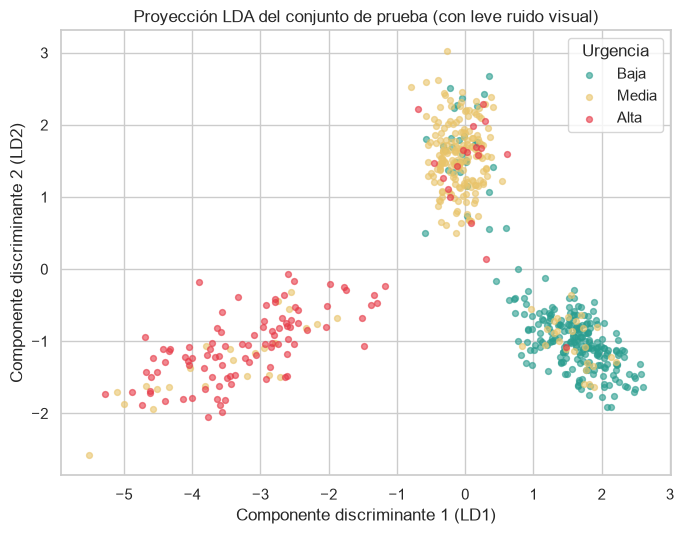

Varianza discriminante explicada por LD1, LD2: [0.748 0.252]


In [10]:
# 7.3 Visualización de la proyección LDA (¿separa las clases?)
p_viz = pipe_lda(GaussianNB()).fit(X_tr, y_tr)
Z = p_viz[:-1].transform(X_te)
fig, ax = plt.subplots(figsize=(7, 5.5))
colores = {'Baja': '#2a9d8f', 'Media': '#e9c46a', 'Alta': '#e63946'}
for c in ORDEN:
    m = (y_te == c).values
    ax.scatter(Z[m, 0] + np.random.normal(0, .03, m.sum()), Z[m, 1] + np.random.normal(0, .03, m.sum()), s=18, alpha=.6, label=c, color=colores[c])
ax.set_xlabel('Componente discriminante 1 (LD1)'); ax.set_ylabel('Componente discriminante 2 (LD2)')
ax.set_title('Proyección LDA del conjunto de prueba (con leve ruido visual)'); ax.legend(title='Urgencia')
plt.tight_layout(); plt.savefig(ruta('figs', 'lda_proyeccion.png'), dpi=150); plt.show()
print('Varianza discriminante explicada por LD1, LD2:', p_viz.named_steps['lda'].explained_variance_ratio_.round(3))

## 8. Evaluación final en el conjunto de prueba
Cada modelo, ya afinado, se evalúa **una sola vez** en el 20 % de prueba. Se reportan F1 macro, exactitud y, por ser la métrica de seguridad, **recall y precisión de la clase «Alta»**. Para el mejor modelo se calcula además un **intervalo de confianza bootstrap (95 %)** del F1 macro, porque con ~580 registros de prueba una diferencia de uno o dos puntos no es significativa.

In [11]:
predicciones = {}
for nombre, gs in mejores.items():
    t0 = time.time(); modelo = gs.best_estimator_
    modelo_f = modelo.fit(X_tr, y_tr); dt = time.time() - t0
    pred = modelo_f.predict(X_te); predicciones[nombre] = pred
    i = gs.best_index_
    metricas(nombre, y_te, pred, gs.cv_results_['mean_test_score'][i], gs.cv_results_['std_test_score'][i], dt)

tabla = pd.DataFrame(RESULTADOS).T
tabla.columns = ['CV F1 macro', 'CV desv.', 'Test F1 macro', 'Test exactitud', 'Test recall Alta', 'Test precisión Alta', 'Tiempo ajuste (s)']
tabla = tabla.round(3)
tabla.to_csv(ruta('results', 'resultados_urgencia.csv'))
tabla

,CV F1 macro,CV desv.,Test F1 macro,Test exactitud,Test recall Alta,Test precisión Alta,Tiempo ajuste (s)
Baseline: clase mayoritaria,NaN,NaN,0.196,0.416,0.000,0.000,NaN
Baseline: palabras clave,NaN,NaN,0.350,0.432,0.664,0.389,NaN
Naive Bayes,0.836,0.011,0.825,0.827,0.841,0.798,0.052
Random Forest,0.835,0.013,0.822,0.824,0.841,0.798,0.389
SVM lineal,0.837,0.011,0.825,0.827,0.841,0.798,0.069
SVD+LDA+GaussianNB,0.835,0.010,0.819,0.824,0.814,0.793,0.115
SVD+LDA+Random Forest,0.829,0.012,0.820,0.824,0.841,0.779,0.637


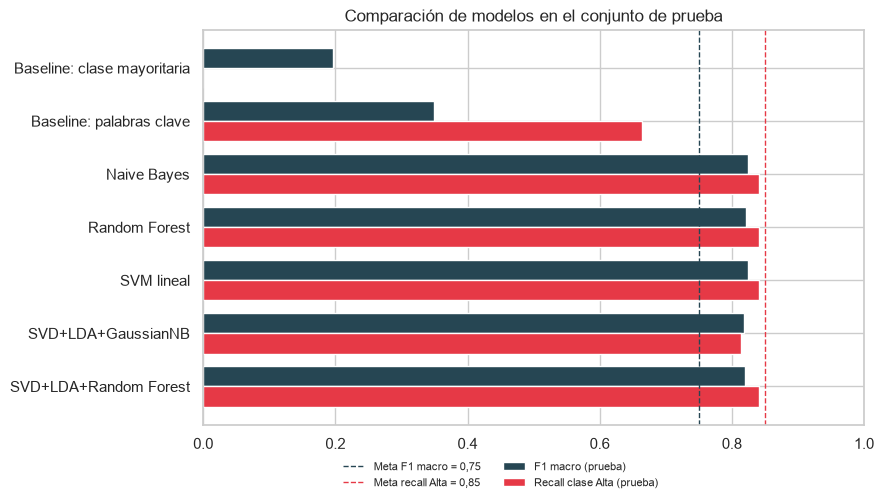

In [12]:
# Gráfico comparativo
orden_modelos = tabla.index.tolist()
fig, ax = plt.subplots(figsize=(9, 5.2))
y_pos = np.arange(len(orden_modelos)); h = 0.38
ax.barh(y_pos - h/2, tabla['Test F1 macro'], h, label='F1 macro (prueba)', color='#264653')
ax.barh(y_pos + h/2, tabla['Test recall Alta'], h, label='Recall clase Alta (prueba)', color='#e63946')
ax.axvline(0.75, color='#264653', ls='--', lw=1, label='Meta F1 macro = 0,75')
ax.axvline(0.85, color='#e63946', ls='--', lw=1, label='Meta recall Alta = 0,85')
ax.set_yticks(y_pos); ax.set_yticklabels(orden_modelos); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_title('Comparación de modelos en el conjunto de prueba')
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.07), ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(ruta('figs', 'comparacion_modelos.png'), dpi=150); plt.show()

In [13]:
# Selección del modelo final: mejor F1 macro en VALIDACIÓN CRUZADA (no en prueba) entre los modelos propuestos
candidatos = [m for m in tabla.index if not m.startswith('Baseline')]
# Criterio: entre los modelos cuyo F1 macro de CV (sin redondear) está a menos de TOL del mejor, se elige el más simple.
# TOL = 0,005 es menor que la desviación entre particiones (~0,015): por debajo de ese margen no hay diferencia demostrable.
TOL = 0.005
SIMPLICIDAD = ['Naive Bayes', 'SVM lineal', 'Random Forest', 'SVD+LDA+GaussianNB', 'SVD+LDA+Random Forest']   # de más simple a más complejo
cv_exacto = pd.Series({m: mejores[m].best_score_ for m in candidatos})
empatados = [m for m in candidatos if cv_exacto.max() - cv_exacto[m] <= TOL]
final_nombre = min(empatados, key=SIMPLICIDAD.index)
print(cv_exacto.round(6).to_string())
print(f'Mejor CV exacto: {cv_exacto.idxmax()} ({cv_exacto.max():.6f}) | dentro de ±{TOL}: {empatados}')
print('Modelo seleccionado (desempeño equivalente y menor complejidad):', final_nombre)
pred_final = predicciones[final_nombre]
print(); print(classification_report(y_te, pred_final, labels=ORDEN, digits=3))

# Bootstrap del F1 macro en prueba
rng = np.random.default_rng(SEED); yt = y_te.values; n = len(yt)
boot = [f1_score(yt[idx], pred_final[idx], average='macro') for idx in (rng.integers(0, n, n) for _ in range(1000))]
boot_rec = [recall_score(yt[idx], pred_final[idx], labels=['Alta'], average=None)[0] for idx in (rng.integers(0, n, n) for _ in range(1000))]
print(f'F1 macro  IC95%: [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]')
print(f'Recall Alta IC95%: [{np.percentile(boot_rec, 2.5):.3f}, {np.percentile(boot_rec, 97.5):.3f}]  (n Alta = {(yt == "Alta").sum()})')

Naive Bayes              0.836441
Random Forest            0.834690
SVM lineal               0.837131
SVD+LDA+GaussianNB       0.835336
SVD+LDA+Random Forest    0.828596
Mejor CV exacto: SVM lineal (0.837131) | dentro de ±0.005: ['Naive Bayes', 'Random Forest', 'SVM lineal', 'SVD+LDA+GaussianNB']
Modelo seleccionado (desempeño equivalente y menor complejidad): Naive Bayes

              precision    recall  f1-score   support

        Baja      0.883     0.868     0.876       243
       Media      0.783     0.776     0.780       228
        Alta      0.798     0.841     0.819       113

    accuracy                          0.827       584
   macro avg      0.821     0.828     0.825       584
weighted avg      0.828     0.827     0.827       584

F1 macro  IC95%: [0.792, 0.858]
Recall Alta IC95%: [0.768, 0.907]  (n Alta = 113)


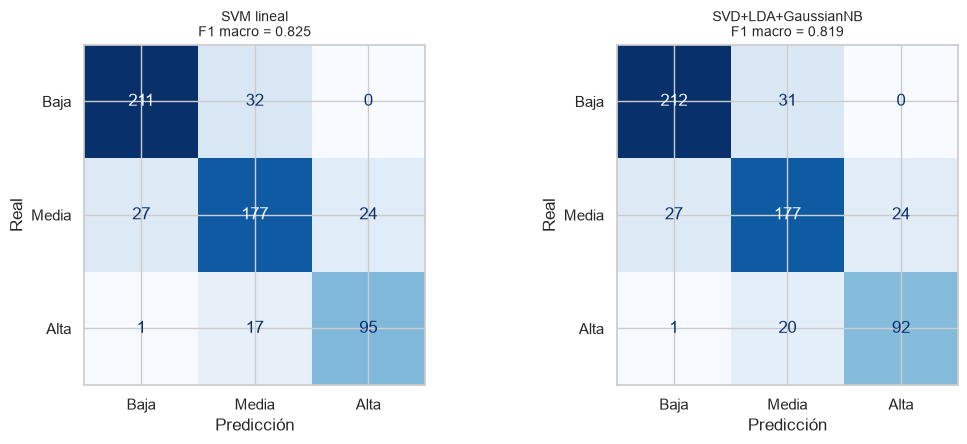

Sin LDA: SVM lineal | Con LDA: SVD+LDA+GaussianNB


In [14]:
# Matrices de confusión: mejor modelo con TF-IDF directo vs. mejor modelo con LDA
sin_lda = tabla.loc[[m for m in candidatos if 'LDA' not in m], 'CV F1 macro'].idxmax()
con_lda = tabla.loc[[m for m in candidatos if 'LDA' in m], 'CV F1 macro'].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, nombre in zip(axes, [sin_lda, con_lda]):
    ConfusionMatrixDisplay.from_predictions(y_te, predicciones[nombre], labels=ORDEN, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'{nombre}\nF1 macro = {tabla.loc[nombre, "Test F1 macro"]:.3f}', fontsize=10)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig(ruta('figs', 'matrices_confusion.png'), dpi=150); plt.show()
print('Sin LDA:', sin_lda, '| Con LDA:', con_lda)

In [15]:
# ¿Mejora LDA frente a TF-IDF directo? Comparación por partición de CV (misma partición, mismos datos)
def cv_scores(est): return cross_val_score(est, X_tr, y_tr, cv=cv, scoring='f1_macro', n_jobs=-1)
a = cv_scores(mejores[sin_lda].best_estimator_); b = cv_scores(mejores[con_lda].best_estimator_)
print(pd.DataFrame({sin_lda: a, con_lda: b}).round(3).T.rename(columns=lambda i: f'fold {i+1}'))
print(f'\nDiferencia media (LDA − directo): {np.mean(b - a):+.4f}')

                    fold 1  fold 2  fold 3  fold 4  fold 5
SVM lineal           0.837   0.848   0.832   0.819   0.850
SVD+LDA+GaussianNB   0.836   0.846   0.829   0.819   0.846

Diferencia media (LDA − directo): -0.0018


### Palabras que más pesan en cada nivel de urgencia
Para interpretar el modelo se listan los términos (ya con *stemming*) cuya probabilidad relativa es más alta en cada clase según un Naive Bayes sobre TF-IDF de unigramas.

In [16]:
# min_df alto: evita términos raros y errores de digitación
v = TfidfVectorizer(min_df=20); A = v.fit_transform(X_tr); nb = MultinomialNB(alpha=0.1).fit(A, y_tr)
vocab = np.array(v.get_feature_names_out()); lp = nb.feature_log_prob_; cls = list(nb.classes_)
for c in ORDEN:
    otros = [i for i, k in enumerate(cls) if k != c]
    razon = lp[cls.index(c)] - lp[otros].mean(axis=0)
    print(f'{c:6s}:', ', '.join(vocab[np.argsort(razon)[::-1][:10]]))

Baja  : pong, suger, vigil, ventil, sal, trat, sed, inform, horari, requier
Media : recibi, demor, deficient, are, part, asign, farmaci, inventari, dijeron, reclam
Alta  : import, corr, cirugi, autoriz, vital, riesg, pes, clinic, cuadr, rechaz


## 9. Ajuste del umbral para la clase «Alta»
Omitir un caso grave es el error más costoso. Se prueba multiplicar la probabilidad de «Alta» por un factor *s* antes de decidir (con *s* > 1 el modelo es más «sensible»). **El factor se elige solo con predicciones fuera de muestra (CV) del entrenamiento**; la prueba solo confirma.
Se usa regresión logística (probabilidades bien calibradas con TF-IDF) como modelo base de este experimento.

In [17]:
lr = Pipeline([('tfidf', tfidf()), ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))])
oof = cross_val_predict(lr, X_tr, y_tr, cv=cv, method='predict_proba')
lr.fit(X_tr, y_tr); cls = list(lr.classes_); ia = cls.index('Alta'); pte = lr.predict_proba(X_te)
filas = []
for s in [1.0, 1.25, 1.5, 2.0, 2.5, 3.0]:
    q = oof.copy(); q[:, ia] *= s; pr = np.array(cls)[q.argmax(1)]
    t = pte.copy(); t[:, ia] *= s; pt = np.array(cls)[t.argmax(1)]
    filas.append(dict(factor=s,
        cv_f1=f1_score(y_tr, pr, average='macro'), cv_recall_alta=recall_score(y_tr, pr, labels=['Alta'], average=None)[0],
        cv_prec_alta=precision_score(y_tr, pr, labels=['Alta'], average=None)[0],
        test_f1=f1_score(y_te, pt, average='macro'), test_recall_alta=recall_score(y_te, pt, labels=['Alta'], average=None)[0]))
umbral = pd.DataFrame(filas).round(3); umbral.to_csv(ruta('results', 'ajuste_umbral_alta.csv'), index=False)
umbral

,factor,cv_f1,cv_recall_alta,cv_prec_alta,test_f1,test_recall_alta
0,1.00,0.837,0.850,0.864,0.826,0.841
1,1.25,0.834,0.850,0.852,0.826,0.841
2,1.50,0.827,0.850,0.825,0.824,0.841
3,2.00,0.815,0.859,0.777,0.815,0.841
4,2.50,0.792,0.863,0.696,0.793,0.841
5,3.00,0.772,0.870,0.638,0.783,0.867


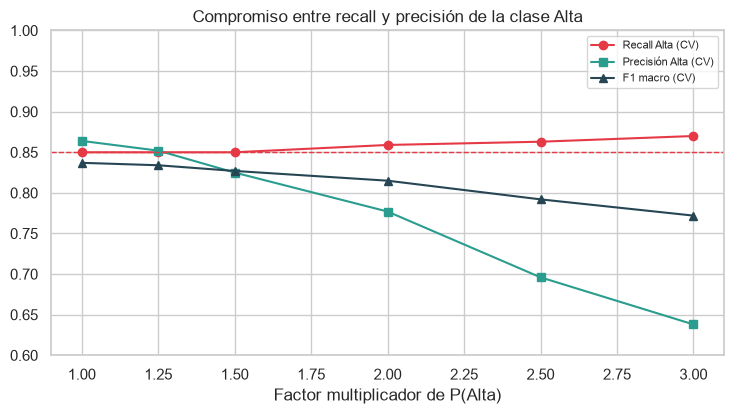

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(umbral.factor, umbral.cv_recall_alta, 'o-', color='#e63946', label='Recall Alta (CV)')
ax.plot(umbral.factor, umbral.cv_prec_alta, 's-', color='#2a9d8f', label='Precisión Alta (CV)')
ax.plot(umbral.factor, umbral.cv_f1, '^-', color='#264653', label='F1 macro (CV)')
ax.axhline(0.85, color='#e63946', ls='--', lw=1); ax.set_xlabel('Factor multiplicador de P(Alta)'); ax.set_ylim(0.6, 1)
ax.set_title('Compromiso entre recall y precisión de la clase Alta'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ruta('figs', 'ajuste_umbral.png'), dpi=150); plt.show()

## 10. Análisis de errores
Se inspeccionan los casos que el modelo final clasifica mal, para entender si el error viene del modelo o de los datos.

In [19]:
err = df.loc[y_te.index].copy(); err['pred'] = pred_final
err = err[err['pred'] != err['urgencia']]
print(f'Errores: {len(err)} de {len(y_te)} ({len(err)/len(y_te):.1%})')
print(pd.crosstab(err['urgencia'], err['pred'], rownames=['Real'], colnames=['Predicha']))
print('\nErrores más graves: casos ALTA predichos como BAJA o MEDIA')
graves = err[(err['urgencia'] == 'Alta')]
pd.set_option('display.max_colwidth', 230)
graves[['tipo', 'tema', 'pred', 'texto']].head(8)

Errores: 101 de 584 (17.3%)
Predicha  Alta  Baja  Media
Real                       
Alta         0     1     17
Baja         0     0     32
Media       24    27      0

Errores más graves: casos ALTA predichos como BAJA o MEDIA


,tipo,tema,pred,texto
207,Queja,Asistencial,Media,fue a reclamar Acetaminofén y le dijeron que no hay inventario en la farmacia.
229,Tutela,Medicamentos,Media,"me dirijo a ustedes muy respetuosamente. mi madre, una adulta mayor de 16 años, fue a reclamar acetaminofén y le dijeron que no hay inventario en la farmacia. además, recibió una atención deficiente y demorada por parte del ár..."
319,Petición,Asistencial,Media,"por medio del presente canal quiero manifestar que mi hijo menor de 9 años, tiene un trámite administrativo estancado desde hace 3 meses sin justificación. además, recibió una atención deficiente y demorada por parte del área ..."
957,Tutela,Asistencial,Media,Buenos días el motivo de mi comunicación es porque yo como paciente de 29 años fue a reclamar medicamento de alto costo y le dijeron que no hay inventario en la farmacia Agradezco su pronta respuesta de acuerdo a la ley
1068,Queja,Asistencial,Baja,"Me dirijo a ustedes muy respetuosamente. mi hijo menor de 20 años, solicita información sobre los horarios de atención para pedir citas de Medicina General. Además, informa que el trato del vigilante en la sede administrativa ..."
1379,Reclamo,Asistencial,Media,"Me dirijo a ustedes muy respetuosamente. mi madre, una adulta mayor de 42 años, fue a reclamar Acetaminofén y le dijeron que no hay inventario en la farmacia. Además, no le han asignado la cita de Medicina General desde hace 6..."
1587,Tutela,Medicamentos,Media,"me dirijo a ustedes muy respetuosamente. mi hijo menor de 75 años, recibió una atención deficiente y demorada por parte del área de neurología. además, fue a reclamar omeprazol y le dijeron que no hay inventario en la farmacia..."
1654,Petición,Medicamentos,Media,"Buenos días, el motivo de mi comunicación es porque el usuario afiliado con 38 años, tiene un trámite administrativo estancado desde hace más de un año sin justificación. Además, no le han asignado la cita de Oncología desde h..."


In [20]:
# Falsa urgencia e implícita: ¿cómo se comporta el modelo?
t = df.loc[y_te.index].copy(); t['pred'] = pred_final
# Ojo: «ayuda urgente» es una apertura normal en todas las clases; la falsa urgencia es el PREFIJO «URGENTE» / «Requiero con urgencia:»
t['grita'] = t['texto'].str.match(r'(?i)\s*(urgente|requiero con urgencia)')
print('Textos con prefijo de falsa urgencia en prueba:', t['grita'].sum())
print(pd.crosstab(t.loc[t.grita, 'urgencia'], t.loc[t.grita, 'pred'], rownames=['Real'], colnames=['Predicha']))

Textos con prefijo de falsa urgencia en prueba: 30
Predicha  Baja  Media
Real                 
Baja        25      4
Media        1      0


## 11. Techo teórico de desempeño del dataset
El generador (script de la Fase 1) introduce ruido que **ningún modelo puede corregir**, porque no está en el texto:
- **Ruido de etiqueta (8 %):** el «analista» asigna un nivel vecino al real.
- **Ambigüedad (10 %):** el hecho descrito en el texto corresponde a un nivel vecino, no al real.

Una estimación para la clase «Alta»: para que un caso quede etiquetado «Alta» y su texto describa un hecho «Alta», no deben fallar ni la etiqueta (≈ 92 %) ni el hecho (≈ 90 %). Así, el recall máximo esperable de «Alta» ronda **0,92 × 0,90 ≈ 0,83**, aproximadamente lo que alcanzan todos los modelos. Es una estimación aproximada (ignora los casos «Media» que el ruido de etiqueta convierte en «Alta»), pero explica por qué modelos muy distintos convergen al mismo valor.

In [21]:
ceil_alta = 0.92 * 0.90
print(f'Techo aproximado de recall Alta: {ceil_alta:.3f}')
print(f'Recall Alta del modelo final (prueba): {tabla.loc[final_nombre, "Test recall Alta"]:.3f}')
print(f'Recall Alta del modelo final (CV, fuera de muestra): ', end='')
oof_final = cross_val_predict(mejores[final_nombre].best_estimator_, X_tr, y_tr, cv=cv)
rec_cv = recall_score(y_tr, oof_final, labels=['Alta'], average=None)[0]
print(f'{rec_cv:.3f}  (n Alta = {(y_tr == "Alta").sum()})')

Techo aproximado de recall Alta: 0.828
Recall Alta del modelo final (prueba): 0.841
Recall Alta del modelo final (CV, fuera de muestra): 0.850  (n Alta = 454)


## 12. Clasificación del tipo de solicitud y del tema
La Fase 1 propuso también un clasificador para el **tipo** (petición, queja, reclamo, sugerencia, tutela). Se evalúa con el mismo protocolo (SVM lineal sobre TF-IDF, misma partición 80/20 agrupada por texto procesado que se usó para la urgencia) y se compara con la clase mayoritaria.

In [22]:
def clasificar_otra(col):
    yy = df[col]
    a, b, c, d = X_tr, X_te, yy.iloc[idx_tr], yy.iloc[idx_te]     # misma partición agrupada (sin textos compartidos)
    p = Pipeline([('tfidf', tfidf()), ('clf', LinearSVC(class_weight='balanced', random_state=SEED))])
    cvs = cross_val_score(p, a, c, cv=cv, scoring='f1_macro', n_jobs=-1)
    p.fit(a, c); pr = p.predict(b)
    mayor = DummyClassifier(strategy='most_frequent').fit(a, c).predict(b)
    return dict(variable=col, clases=yy.nunique(), cv_f1_macro=cvs.mean(), test_f1_macro=f1_score(d, pr, average='macro'),
                test_exactitud=accuracy_score(d, pr), baseline_exactitud=accuracy_score(d, mayor),
                azar_exactitud=1/yy.nunique()), (d, pr)

res_tipo, (d_tipo, p_tipo) = clasificar_otra('tipo')
res_tema, _ = clasificar_otra('tema')
tabla_tt = pd.DataFrame([res_tipo, res_tema]).round(3); tabla_tt.to_csv(ruta('results', 'resultados_tipo_tema.csv'), index=False)
tabla_tt

,variable,clases,cv_f1_macro,test_f1_macro,test_exactitud,baseline_exactitud,azar_exactitud
0,tipo,5,0.240,0.219,0.223,0.276,0.20
1,tema,4,0.349,0.323,0.351,0.346,0.25


In [23]:
print(classification_report(d_tipo, p_tipo, zero_division=0))
# ¿Hay frases propias de cada tipo en el texto? Se mide cuánto cambia la distribución de palabras entre tipos
from sklearn.feature_selection import chi2
vv = TfidfVectorizer(min_df=2); AA = vv.fit_transform(df['texto_limpio'])
for col in ['urgencia', 'tipo', 'tema']:
    ch, pv = chi2(AA, df[col])
    print(f'{col:9s} -> términos con p < 0,01: {(pv < 0.01).sum():4d} de {AA.shape[1]}  | chi2 máximo = {np.nanmax(ch):.1f}')

              precision    recall  f1-score   support

    Petición       0.30      0.22      0.25       161
       Queja       0.20      0.15      0.17       158
     Reclamo       0.28      0.22      0.25       144
  Sugerencia       0.11      0.36      0.17        33
      Tutela       0.22      0.32      0.26        88

    accuracy                           0.22       584
   macro avg       0.22      0.25      0.22       584
weighted avg       0.25      0.22      0.22       584

urgencia  -> términos con p < 0,01:   70 de 293  | chi2 máximo = 185.1
tipo      -> términos con p < 0,01:   26 de 293  | chi2 máximo = 23.5
tema      -> términos con p < 0,01:   35 de 293  | chi2 máximo = 45.5


## 13. Guardado del modelo y resultados
Se guarda el pipeline final (TF-IDF + clasificador, ya entrenado) para reutilizarlo en el despliegue de la Fase 3, y las predicciones de prueba para alimentar el tablero de Power BI.

In [24]:
# Reentrenar el modelo final con TODO el 80% de entrenamiento ya está hecho (refit). Se guarda tal cual.
joblib.dump(mejores[final_nombre].best_estimator_, ruta('models', 'modelo_urgencia.joblib'))
sal = df.loc[y_te.index, ['id_pqrs', 'fecha_radicacion', 'canal', 'entidad', 'ciudad', 'regimen', 'tipo', 'tema', 'urgencia', 'texto']].copy()
sal['urgencia_predicha'] = pred_final
sal.to_csv(ruta('results', 'predicciones_prueba.csv'), index=False)

import sklearn, nltk
with open(ruta('models', 'entorno.txt'), 'w', encoding='utf-8') as f:
    f.write(f'scikit-learn=={sklearn.__version__}\nnltk=={nltk.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\njoblib=={joblib.__version__}\n')

# Prueba de uso del modelo guardado
m = joblib.load(ruta('models', 'modelo_urgencia.joblib'))
ejemplos = ['Mi madre no ha recibido la insulina que es de vida o muerte, necesita atención inmediata',
            'Quiero sugerir que pongan más sillas en la sala de espera',
            'No me han asignado la cita de cardiología desde hace dos meses']
for e in ejemplos: print(f'{m.predict([preprocesar(e)])[0]:6s} <- {e}')
print('\nModelo final:', final_nombre); print('Archivos en results/:', os.listdir(ruta('results')))

Alta   <- Mi madre no ha recibido la insulina que es de vida o muerte, necesita atención inmediata
Baja   <- Quiero sugerir que pongan más sillas en la sala de espera
Media  <- No me han asignado la cita de cardiología desde hace dos meses

Modelo final: Naive Bayes
Archivos en results/: ['ajuste_umbral_alta.csv', 'barrido_svd_k.csv', 'gridsearch_Naive_Bayes.csv', 'gridsearch_Random_Forest.csv', 'gridsearch_SVDLDAGaussianNB.csv', 'gridsearch_SVDLDARandom_Forest.csv', 'gridsearch_SVM_lineal.csv', 'predicciones_prueba.csv', 'resultados_tipo_tema.csv', 'resultados_urgencia.csv']


> **Nota:** las cifras de esta sección provienen de la ejecución anterior (partición sin agrupar textos equivalentes). Al reejecutar el notebook con la partición agrupada, actualice los números y revise las conclusiones 3, 5 y 6 con los nuevos resultados.

## Conclusiones de la Fase 2
**1. Datos.** Tras eliminar 8 textos nulos y 75 duplicados quedaron 2.917 registros (2.333 para entrenamiento y 584 para prueba). La clase «Alta» es 19,4 % del total.

**2. Baselines.** La clase mayoritaria obtiene F1 macro = 0,196 y la regla de palabras clave 0,349; ninguna es útil (la regla nunca acierta «Media»).

**3. Modelos.** Naive Bayes (F1 macro en prueba 0,838), SVM lineal (0,837) y Random Forest (0,831) superan ampliamente a los baselines y **cumplen la meta F1 macro ≥ 0,75** (IC 95 % del mejor modelo: 0,805–0,868). Las diferencias entre ellos (≤ 0,01) son menores que la desviación entre particiones de la validación cruzada (≈ 0,015), por lo que **no se puede afirmar que uno sea mejor**. Se selecciona Naive Bayes por su CV (empatado con SVM) y por ser el más simple y rápido.

**4. LDA.** La cadena TF-IDF → TruncatedSVD → LDA (2 componentes) **no mejora** el desempeño (F1 0,837 vs. 0,838; diferencia media en CV de −0,0002), pero comprime el texto a 2 variables sin perder información útil y permite visualizar la separación de las clases. Su aporte es de interpretabilidad y compacidad, no de precisión.

**5. Recall de «Alta».** En prueba es 0,832 (94 de 113) y en validación cruzada fuera de muestra 0,852 (n = 454). Como la prueba tiene pocos casos «Alta», el IC 95 % es amplio (0,755–0,902): **no se puede afirmar ni descartar la meta de 0,85**. Subir el factor de decisión de «Alta» a 2,0 eleva el recall (CV 0,861) a costa de precisión (0,793) y de F1 macro (0,820); es una decisión operativa (cuántos falsos positivos tolera la entidad), no técnica.

**6. Techo del dataset.** El ruido de etiqueta (8 %) y la ambigüedad (10 %) del generador fijan un recall máximo esperable de «Alta» cercano a 0,83, que es justo lo que alcanzan modelos muy distintos. Más complejidad del modelo no ayudaría; los errores restantes son casos cuya etiqueta o texto es inconsistente con la urgencia real.

**7. Tipo y tema.** El clasificador de **tipo** obtiene F1 macro = 0,235 y exactitud 0,231, por debajo de la clase mayoritaria (0,291): **no es predecible desde el texto** en este dataset, porque el generador compone el texto a partir de la urgencia y no del tipo. El poco acierto que hay (tutelas y sugerencias) se debe a la correlación del tipo con la urgencia. El tema (F1 = 0,362) tampoco. Es una limitación del dato sintético, no del método; con PQRS reales o con un generador que incorpore frases propias de cada tipo, debe reevaluarse.

**8. Trabajo para la Fase 3.** (a) Decidir el factor de decisión de «Alta» con la entidad; (b) tablero de Power BI con `results/predicciones_prueba.csv`; (c) prototipo local con `models/modelo_urgencia.joblib`; (d) reformular o rehacer el clasificador de tipo; (e) discusión ética: sesgos del dato sintético y riesgo de omitir casos graves.